In [2]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy as sp
import sklearn

sys.version, np.__version__, pd.__version__, matplotlib.__version__, sp.__version__, sklearn.__version__

('3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]',
 '2.5.4',
 '3.1.1',
 '3.11.2',
 '1.18.1',
 '1.9.1')

## Постановка задачи
Нужно спрогнозировать месячные продажи 1656 товаров на три месяца вперед на декабрь 2021, январь 2022 и февраль 2022.

In [3]:
train = pd.read_csv('E:/kaggle_mamo/data/train.csv')

train.head()

,sku,unit,2019-01,2019-02,2019-03,2019-04,2019-05,2019-06,2019-07,2019-08,...,2021-02,2021-03,2021-04,2021-05,2021-06,2021-07,2021-08,2021-09,2021-10,2021-11
0,0,ШТ,128.0,125.0,179.0,199.0,204.0,246.0,172.0,235.0,...,379.0,250.0,317.0,172.0,193.0,173.0,121.0,318.0,328.0,208.0
1,1,ШТ,65.0,64.0,54.0,91.0,74.0,91.0,138.0,115.0,...,68.0,65.0,72.0,82.0,85.0,69.0,75.0,100.0,72.0,89.0
2,2,ШТ,157.0,205.0,210.0,205.0,265.0,248.0,292.0,268.0,...,334.0,380.0,409.0,309.0,388.0,438.0,404.0,293.0,274.0,381.0
3,3,ШТ,2450.0,2280.0,2144.0,2283.0,2177.0,2888.0,3066.0,2288.0,...,2806.0,2085.0,1984.0,2086.0,2871.0,2204.0,1821.0,2187.0,1672.0,1665.0
4,4,ШТ,119.0,154.0,154.0,270.0,513.0,718.0,720.0,292.0,...,222.0,258.0,289.0,662.0,759.0,616.0,365.0,321.0,392.0,409.0


In [5]:
train.shape

(1656, 37)

In [7]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1656 entries, 0 to 1655
Data columns (total 37 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   sku      1656 non-null   int64  
 1   unit     1656 non-null   str    
 2   2019-01  1656 non-null   float64
 3   2019-02  1656 non-null   float64
 4   2019-03  1656 non-null   float64
 5   2019-04  1656 non-null   float64
 6   2019-05  1656 non-null   float64
 7   2019-06  1656 non-null   float64
 8   2019-07  1656 non-null   float64
 9   2019-08  1656 non-null   float64
 10  2019-09  1656 non-null   float64
 11  2019-10  1656 non-null   float64
 12  2019-11  1656 non-null   float64
 13  2019-12  1656 non-null   float64
 14  2020-01  1656 non-null   float64
 15  2020-02  1656 non-null   float64
 16  2020-03  1656 non-null   float64
 17  2020-04  1656 non-null   float64
 18  2020-05  1656 non-null   float64
 19  2020-06  1656 non-null   float64
 20  2020-07  1656 non-null   float64
 21  2020-08  1656 non-null   

**Какие данные есть:** есть выборка с продажами товаров. 1656 товаров в 14 единицах измерения. История продаж за 35 месяцев с января 2019 по ноябрь 2021. Все признаки числовые кроме unit (тип str).

In [10]:
train['unit'].value_counts()

unit
ШТ     1232
УП      139
Меш      69
КГ       52
Лст      47
Пм       27
РУЛ      23
М        21
ПАР      17
Вдр      17
ПК        5
Кмп       4
Мкр       2
Бнк       1
Name: count, dtype: int64

Большинство товаров измеряются в штуках. Это значит, что мы не можем просто складывать все продажи в кучу, то есть нельзя складывать штуки с килограммами.

In [8]:
train.isna().sum()

sku        0
unit       0
2019-01    0
2019-02    0
2019-03    0
2019-04    0
2019-05    0
2019-06    0
2019-07    0
2019-08    0
2019-09    0
2019-10    0
2019-11    0
2019-12    0
2020-01    0
2020-02    0
2020-03    0
2020-04    0
2020-05    0
2020-06    0
2020-07    0
2020-08    0
2020-09    0
2020-10    0
2020-11    0
2020-12    0
2021-01    0
2021-02    0
2021-03    0
2021-04    0
2021-05    0
2021-06    0
2021-07    0
2021-08    0
2021-09    0
2021-10    0
2021-11    0
dtype: int64

**Пропуски:** не обнаружены.

In [12]:
train.describe()

,sku,2019-01,2019-02,2019-03,2019-04,2019-05,2019-06,2019-07,2019-08,2019-09,...,2021-02,2021-03,2021-04,2021-05,2021-06,2021-07,2021-08,2021-09,2021-10,2021-11
count,1656.000000,1656.000000,1656.000000,1656.000000,1656.000000,1656.000000,1656.000000,1656.000000,1656.000000,1656.000000,...,1656.000000,1656.000000,1656.000000,1656.000000,1656.000000,1656.000000,1656.000000,1656.000000,1656.000000,1656.000000
mean,827.500000,1158.567633,1137.100845,1439.812198,1979.579710,2630.389493,2978.982488,3276.943237,3222.805556,2935.452295,...,1653.480072,2161.763285,2729.247585,3426.312198,3581.771739,3560.342995,3543.610507,3298.089976,3001.282609,2486.432971
std,478.190339,7691.937251,7790.303943,9343.824834,11980.515273,14309.365521,16301.270305,16947.678931,16710.997254,14894.351740,...,8673.550098,10973.909404,13896.688843,19950.268069,16945.978437,16702.387875,16878.625661,14023.956093,13562.131982,12490.203360
min,0.000000,0.000000,0.000000,0.000000,0.000000,-5.000000,0.000000,0.000000,0.000000,0.000000,...,-400.000000,-14.000000,0.000000,-25.000000,0.000000,-6564.000000,-2.000000,0.000000,-265.000000,0.000000
25%,413.750000,35.000000,43.000000,64.000000,93.000000,117.750000,130.000000,147.750000,155.000000,137.750000,...,105.000000,132.000000,175.000000,194.750000,203.000000,203.000000,215.000000,204.000000,188.750000,148.500000
50%,827.500000,128.000000,125.000000,162.500000,232.000000,301.500000,318.000000,355.500000,360.500000,321.500000,...,235.000000,293.000000,395.500000,423.000000,439.500000,440.000000,468.000000,449.000000,421.500000,365.000000
75%,1241.250000,389.750000,379.500000,486.500000,707.250000,915.000000,961.500000,1040.750000,1105.500000,972.500000,...,656.000000,866.750000,1153.250000,1293.000000,1320.000000,1262.750000,1272.000000,1274.500000,1191.000000,1042.250000
max,1655.000000,192460.000000,184571.000000,246939.000000,295634.000000,307078.000000,386867.000000,356380.000000,308391.000000,287573.000000,...,179375.000000,212838.000000,276107.000000,582794.000000,348309.000000,334899.000000,321021.000000,257766.000000,270526.000000,320434.000000


**Анализ описательной статистики**
1. В некоторых месяцах минимальные значения отрицательные. Скорее всего возвраты.
2. Также минимум почти везде 0. Значит скорее всего есть товары, которые не продавались.
3. Сильный разброс между mean и std. Подтверждаются слова о том, что 10% товаров дают 80% выручки.

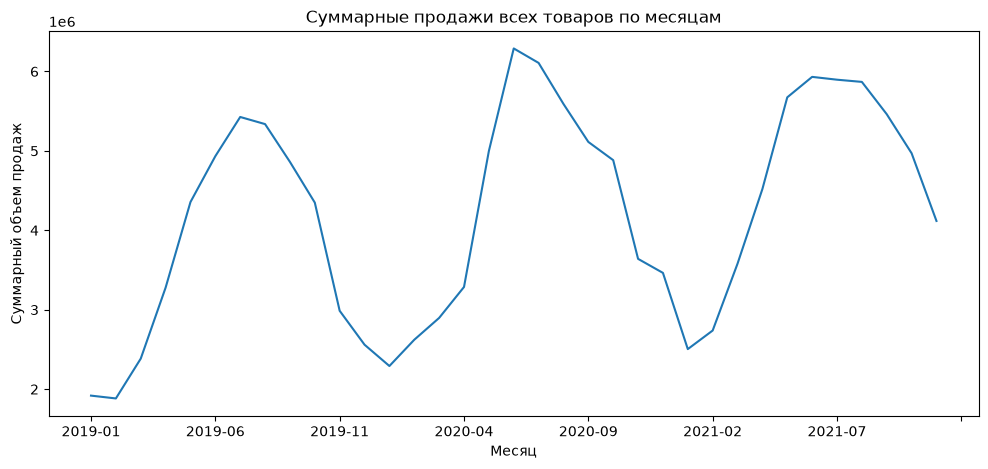

In [24]:
dates = train.columns[2:]
sum_by_month = train[dates].sum()

sum_by_month.plot(figsize=(12, 5))
plt.xlabel('Месяц')
plt.ylabel('Суммарный объем продаж')
plt.title('Суммарные продажи всех товаров по месяцам')
plt.show()

**Анализ графика:** есть сезонность, основные пики продаж приходятся на летние месяцы, а самые провальные точки на зиму. Есть восходящий тренд.

Теперь хочу убедиться, что 10% товаров дают 80% выручки.

In [30]:
#общая сумма продаж для каждого товара 
total_scu_sales = train[dates].sum(axis=1)

#так как функция sort_values по умолчанию сортирует данные от меньшего к большему, поэтому надо задать ascending=False
sorted_sales = total_scu_sales.sort_values(ascending=False)

#1656 * 0.1 = 165.5, первые 10% товаров
top_10_persent = sorted_sales.head(166).sum()
total_sales_all = sorted_sales.sum()
share_10_persent = (top_10_persent / total_sales_all) * 100

print("Доля топ 10% товаров в продажах:", round(share_10_persent,2))

Доля топ 10% товаров в продажах: 80.11


Это подтверждает сильный дисбаланс данных. Метрика WAPE будет сильно зависеть от качества прогноза именно для этих 166 товаров. Ошибки на мелких товарах почти не повлияют на общую метрику.

Теперь посчитаем количество нулей и отрицательных значений.

In [36]:
zeros_count = (train[dates].values == 0).sum()
negative_count = (train[dates].values < 0).sum()
total_cells = train[dates].size

print("Всего ячеек", total_cells)
print("Количество нулей", zeros_count, "В процентах", round(zeros_count / total_cells * 100, 2))
print("Количество отрицательных значений", negative_count, "В процентах", round(negative_count / total_cells * 100, 2))

Всего ячеек 57960
Количество нулей 3351 В процентах 5.78
Количество отрицательных значений 21 В процентах 0.04


**Анализ:** количество нулей около 6%, а отрицательные значения встречаются очень редко их можно заменить на 0.

In [40]:
zeros_count = (train[dates] == 0).sum()
negative_count = (train[dates] < 0).sum()
total_cells = train[dates].size

print("Всего ячеек", total_cells)
print("Количество нулей", zeros_count)

Всего ячеек 57960
Количество нулей 2019-01    212
2019-02    210
2019-03    195
2019-04    175
2019-05    164
2019-06    164
2019-07    151
2019-08    142
2019-09    146
2019-10    143
2019-11    142
2019-12    142
2020-01    138
2020-02    127
2020-03    117
2020-04    112
2020-05    105
2020-06    104
2020-07     91
2020-08     83
2020-09     70
2020-10     60
2020-11     60
2020-12     56
2021-01     59
2021-02     32
2021-03     26
2021-04     20
2021-05     16
2021-06     15
2021-07     15
2021-08     15
2021-09     13
2021-10     13
2021-11     18
dtype: int64


Если просмотреть по месяцам отдельно, можно заметить, что больше всего нулей в 2019 году.

In [44]:
#сначала суммируем месяцы для каждого товара, затем складываем эти суммы по категориям
unit_sales = train.groupby('unit')[dates].sum().sum(axis=1)

unit_sales_percent = (unit_sales / unit_sales.sum() * 100).sort_values(ascending=False)

print(unit_sales_percent)

unit
ШТ     85.748421
Меш     3.349108
Пм      3.125545
М       2.140503
Лст     1.568667
ПАР     1.432383
УП      1.330860
КГ      0.845042
РУЛ     0.189709
Вдр     0.164387
ПК      0.075623
Кмп     0.012708
Мкр     0.012619
Бнк     0.004424
dtype: float64


**Анализ:** лидером по объему продаж являются штучные товары, на них приходится почти 86%. У остальных категорий незначительная доля. То есть для расчета WAPE будут приоритетом штучные товары.

### Общий вывод по разведочному анализу
В ходе анализа данных были выявлены следующие ключевые особенности:
1. **Сезонность и тренд:** продажи имеют ярко выраженную годовую сезонность и общий восходящий тренд.
2. **Дисбаланс:** топ-10% товаров генерируют 80% всего объема продаж. Это значит, что метрика WAPE будет крайне чувствительна к ошибкам на этих крупных товарах, а мелкие товары почти не повлияют на общую оценку.
3. **Единицы измерения:** почти 86% объема приходится на товары в штуках. Остальные категории занимают незначительную долю.
4. **Аномалии:** 
   - Около 6% значений  нули.
   - Отрицательные значения составляют всего 0.04%, их можно заменить на 0.
   - Пропусков в данных нет.

**Что это значит для моделирования:** при построении модели нужно обязательно учесть годовую сезонность и сфокусироваться на точности прогноза для крупных товаров, чтобы минимизировать WAPE. Для мелких товаров надо использовать простые модели, чтобы не испортить MASE.